# Avance 1: Análisis Exploratorio de Datos (EDA) - Autolavado Expréss La Estancia
* **Variable Objetivo:** `Precio ($)` y demanda diaria (`Total Vehículos Lavados`) — Problema de **Regresión**.
* **Justificación:** Optimizar turnos laborales y compra de insumos (shampoo, cera) prediciendo la afluencia en días pico.

Total de registros limpios: 103,309


C:\Users\josea\AppData\Local\Temp\ipykernel_31824\2938165148.py:14: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


,precio,hora_num
count,103309.000000,103309.000000
mean,96.043423,12.538240
std,27.678195,3.101699
min,70.000000,8.000000
25%,90.000000,10.000000
50%,90.000000,12.000000
75%,110.000000,15.000000
max,550.000000,18.000000


C:\Users\josea\AppData\Local\Temp\ipykernel_31824\2938165148.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='dia_semana', order=orden_dias, ax=axes[1], palette='viridis')


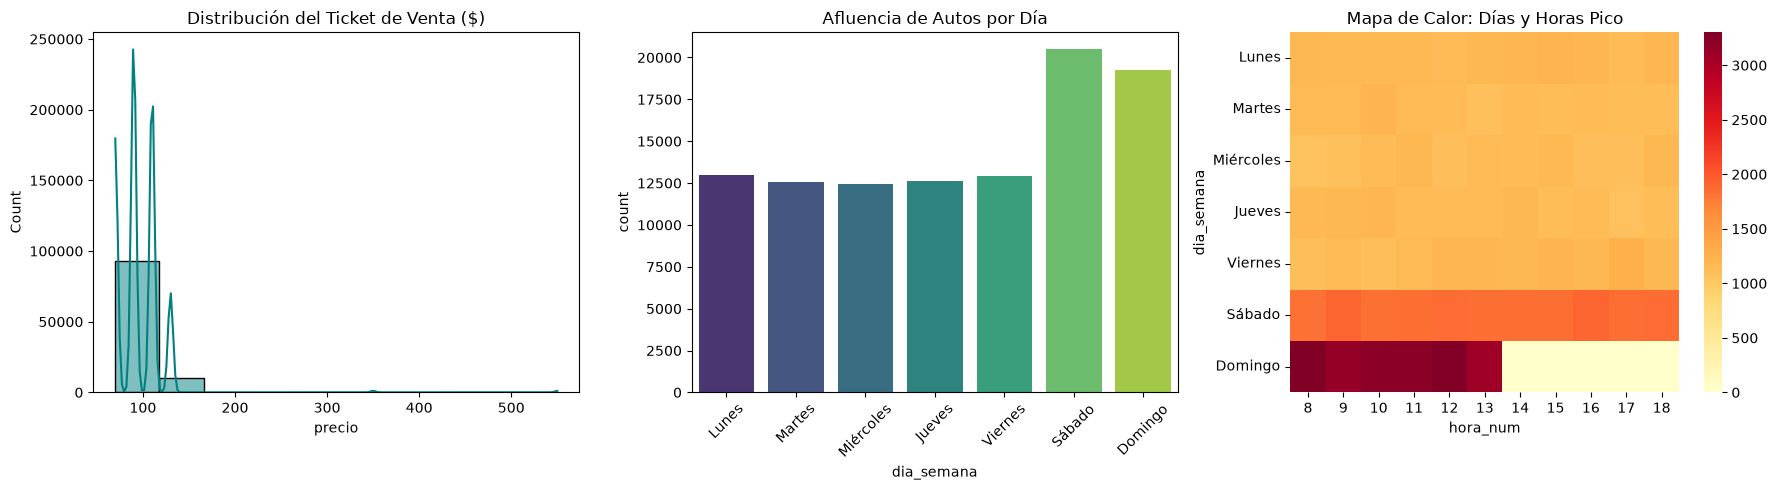

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar dataset real
df = pd.read_excel('Registro_Ventas_Autolavado_v3 (1).xlsx', sheet_name=0, skiprows=2)
df.columns = ['id_ticket', 'fecha', 'dia_semana', 'hora', 'servicio', 'precio']

# Limpieza de nulos y formatos
df = df[df['id_ticket'] != 'ID Ticket'].copy()
df['precio'] = pd.to_numeric(df['precio'], errors='coerce')
df['fecha'] = pd.to_datetime(df['fecha'])
df['hora_num'] = pd.to_datetime(df['hora'], format='%H:%M').dt.hour
df.dropna(inplace=True)

print(f"Total de registros limpios: {len(df):,}")
display(df[['precio', 'hora_num']].describe())

# Gráficas EDA
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['precio'], bins=10, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Distribución del Ticket de Venta ($)')

orden_dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
sns.countplot(data=df, x='dia_semana', order=orden_dias, ax=axes[1], palette='viridis')
axes[1].set_title('Afluencia de Autos por Día')
axes[1].tick_params(axis='x', rotation=45)

tabla_calor = pd.crosstab(df['dia_semana'], df['hora_num']).reindex(orden_dias)
sns.heatmap(tabla_calor, cmap='YlOrRd', ax=axes[2])
axes[2].set_title('Mapa de Calor: Días y Horas Pico')

plt.tight_layout()
plt.show()